# Auswertung instationärer Pumpversuche nach Theis und Cooper–Jacob

**Hydraulische Methoden · Hydrogeologie · Karlsruher Institut für Technologie (KIT)**

Dieses Notebook zeigt zwei Verfahren zur Auswertung instationärer Pumpversuche in einem **gespannten Grundwasserleiter**: die Anpassung der vollständigen **Theis-Lösung** und das **Cooper–Jacob-Geradlinienverfahren**. Außerdem wird eine Absenkung für vorgegebene Aquiferparameter berechnet.

### Lernziele

Nach der Bearbeitung können Sie:

1. eine Absenkungszeitreihe mit der Theis-Gleichung berechnen und grafisch darstellen;
2. die Transmissivität **T** und den Speicherkoeffizienten **S** aus Messdaten abschätzen;
3. die Theis-Anpassung in einem **doppellogarithmischen** und die Cooper–Jacob-Auswertung in einem **halblogarithmischen** Diagramm darstellen;
4. die Gültigkeit der Cooper–Jacob-Näherung anhand des Parameters **u** prüfen und die Auswirkungen der Messpunktauswahl beurteilen.

**Benötigte Pakete:** `numpy`, `scipy`, `matplotlib`. Alle Messdaten sind im Notebook enthalten. Führen Sie die Zellen von oben nach unten aus.

*Grundlage:* [Christian Hill: Linear and non-linear fitting of the Theis equation](https://scipython.com/blog/linear-and-non-linear-fitting-of-the-theis-equation/); für den Kurs überarbeitet und ergänzt.

## 1. Theoretische Grundlagen

### 1.1 Theis-Gleichung

Die Theis-Gleichung beschreibt die zeitabhängige Absenkung infolge einer konstanten Grundwasserentnahme:

$$
\boxed{s(u)=\frac{Q}{4\pi T}\,W(u)}
\qquad\text{mit}\qquad
\boxed{u=\frac{r^2 S}{4Tt}}
$$

Die Brunnenfunktion **W(u)** entspricht dem Exponentialintegral:

$$
W(u)=E_1(u)=\int_u^\infty\frac{e^{-x}}{x}\,\mathrm{d}x
$$

| Symbol | Bedeutung | Einheit |
|:---:|:---|:---:|
| **s** | Absenkung | m |
| **r** | Entfernung zur Entnahmestelle | m |
| **t** | Zeit seit Pumpbeginn | s |
| **Q** | Konstante Entnahmerate (Entnahme positiv) | m³/s |
| **T** | Transmissivität | m²/s |
| **S** | Speicherkoeffizient | – |
| **u** | Dimensionsloser Zeitparameter | – |

**Voraussetzungen:** gespannter, homogener und isotroper Grundwasserleiter, radialer Fluss, volle Brunnenerschließung, konstante Entnahmerate, anfänglich horizontaler Grundwasserspiegel und keine wirksamen hydraulischen Ränder. Effekte wie Brunnenspeicherung, Leckage oder Brunnenverluste sind nicht Bestandteil der Lösung.

### 1.2 Cooper–Jacob-Näherung

Für kleine Werte von **u** kann die Brunnenfunktion mit der Reihenentwicklung angenähert werden:

$$
W(u)\approx-\gamma-\ln(u),
\qquad \gamma\approx0{,}577216
$$

Hierbei ist **γ** die **Euler-Mascheroni-Konstante**. Einsetzen in die Theis-Gleichung ergibt:

$$
\boxed{s(u)\approx\frac{Q}{4\pi T}\left[-\gamma-\ln(u)\right]}
$$

Mit dem dekadischen Logarithmus und dem Zusammenhang zwischen **u** und **t** folgt:

$$
\boxed{s(u)\approx\frac{2{,}303\,Q}{4\pi T}
\log_{10}\!\left(\frac{2{,}25\,Tt}{r^2S}\right)}
$$

Das ist eine Gerade, wenn **s** gegen den Logarithmus der Zeit **t** aufgetragen wird. Aus der Steigung **m** (Absenkungszunahme je logarithmischer Dekade) und dem extrapolierten Zeitpunkt **t₀** bei **s = 0** ergeben sich:

$$
\boxed{T=\frac{Q\ln(10)}{4\pi m}}
\qquad\text{und}\qquad
\boxed{S=\frac{4e^{-\gamma}Tt_0}{r^2}\approx\frac{2{,}25\,Tt_0}{r^2}}
$$

**Gültigkeitsbereich der Cooper–Jacob-Näherung:** Die Näherung gilt für kleine Werte von **u**. In der Fachliteratur finden sich unterschiedliche Richtwerte: **u ≤ 0,01** (Kruseman & de Ridder, 1990/1991), **u ≤ 0,02** (Freeze & Cherry, 1979) und **u ≤ 0,05** (Fetter, 2001; zusammengestellt und diskutiert bei Gomo, 2020). Im Folgenden verwenden wir **u ≤ 0,02**. Der Grenzwert ist eine Konvention zur Beurteilung der Näherung und kein statistisches Auswahlverfahren. Eine optisch überzeugende Gerade belegt die Gültigkeit der zugrunde liegenden Modellannahmen nicht. Da **T** und **S** bei einem realen Pumpversuch zunächst unbekannt sind, prüfen wir **u** erst nach der Parameterschätzung.

## 2. Python-Funktionen

Die Theis-Funktion wird mit `scipy.special.exp1` berechnet. Die vollständige Theis-Lösung wird mit einer nichtlinearen Kleinste-Quadrate-Anpassung bestimmt. Dafür optimieren wir die **Logarithmen von S und T**, sodass die geschätzten Parameter positiv bleiben.

Für Cooper–Jacob verwenden wir eine lineare Regression zwischen **s** und `log10(t)`. Über `n_exclude` lässt sich einstellen, wie viele **erste Messpunkte** ausgeschlossen werden. Die Funktion gibt auch die Steigung und den Zeitachsenabschnitt aus. Der Anpassungsfehler wird als **RMSE** berechnet.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import exp1

# Einheitliche Gestaltung der Abbildungen
plt.rcParams.update({
    "figure.figsize": (9, 5.3),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.frameon": False,
})

U_LIMIT = 0.02  # Gewählter Richtwert (Freeze & Cherry, 1979)


def theis_drawdown(t, Q, r, S, T):
    """Berechnet die Absenkung nach Theis (s in m; t in s)."""
    t = np.asarray(t, dtype=float)
    if np.any(t <= 0) or min(Q, r, S, T) <= 0:
        raise ValueError("Q, r, S, T und die Zeiten müssen positiv sein.")
    u = r**2 * S / (4 * T * t)
    return Q / (4 * np.pi * T) * exp1(u)


def rmse(observed, predicted):
    """Root Mean Square Error der Absenkungen (m)."""
    return np.sqrt(np.mean((np.asarray(observed) - np.asarray(predicted))**2))


def fit_theis(t, s, Q, r, S0=1e-3, T0=1e-3):
    """Nichtlineare Anpassung der vollständigen Theis-Lösung."""
    def model(time, logS, logT):
        return theis_drawdown(time, Q, r, np.exp(logS), np.exp(logT))

    result, _ = curve_fit(
        model, t, s, p0=np.log([S0, T0]),
        bounds=(np.log([1e-12, 1e-12]), np.log([10.0, 10.0])),
        max_nfev=10000,
    )
    return tuple(np.exp(result))  # S, T


def fit_cooper_jacob(t, s, Q, r, n_exclude=3):
    """Cooper-Jacob-Gerade aus den Messwerten ab Index n_exclude."""
    t = np.asarray(t, dtype=float)
    s = np.asarray(s, dtype=float)
    if t.ndim != 1 or len(t) != len(s) or np.any(np.diff(t) <= 0):
        raise ValueError("t und s müssen gleich lange Arrays mit aufsteigenden Zeiten sein.")
    if min(Q, r) <= 0 or np.any(t <= 0):
        raise ValueError("Q, r und t müssen positiv sein.")
    if not isinstance(n_exclude, (int, np.integer)) or n_exclude < 0:
        raise ValueError("n_exclude muss eine nichtnegative ganze Zahl sein.")
    if len(t) - n_exclude < 3:
        raise ValueError("Mindestens drei Messpunkte sind für die Regression erforderlich.")

    selected = np.arange(len(t)) >= n_exclude
    m, c = np.polyfit(np.log10(t[selected]), s[selected], 1)
    if m <= 0:
        raise ValueError("Die Steigung muss positiv sein.")

    T = Q * np.log(10) / (4 * np.pi * m)
    t0 = 10 ** (-c / m)
    S = 4 * np.exp(-np.euler_gamma) * T * t0 / r**2
    return {"S": S, "T": T, "m": m, "c": c, "t0": t0, "selected": selected}


def cj_drawdown(t, result):
    """Geradenwert der Cooper-Jacob-Regressionsgeraden."""
    return result["m"] * np.log10(np.asarray(t, dtype=float)) + result["c"]


def check_cj_validity(t, Q, r, fit, limit=U_LIMIT):
    """u-Werte der ausgewählten Messpunkte, aus CJ-Parametern berechnet."""
    times = np.asarray(t)[fit["selected"]]
    u = r**2 * fit["S"] / (4 * fit["T"] * times)
    n_ok = np.count_nonzero(u <= limit)
    n_total = len(u)
    print(f"Gültigkeitsprüfung der Cooper–Jacob-Näherung (u ≤ {limit:.2f})")
    print(f"  Verwendete Messpunkte: {n_total}")
    print(f"  Davon erfüllen das Kriterium: {n_ok}")
    print(f"  Größter u-Wert: {u.max():.4f}")
    if n_ok < n_total:
        print("  ACHTUNG: Einige Punkte überschreiten den gewählten u-Richtwert.")
    else:
        print("  Alle verwendeten Messpunkte erfüllen das u-Kriterium.")
    return u

## 3. Beispiel 1 – synthetische Pumpversuchsdaten

Wir erzeugen Absenkungen mit **bekannten** Werten für **T** und **S** und fügen einen kleinen Messfehler hinzu. Durch den festgelegten Zufalls-Seed sind die Messdaten bei jedem Neustart des Notebooks gleich. Die Parameter können im folgenden Code verändert werden.

In [2]:
# Eingabedaten des ursprünglichen Beispiels
Q_synth = 0.002   # m³/s
r_synth = 10.0    # m
S_true = 0.001    # –
T_true = 0.001    # m²/s
t_synth = np.array([20, 40, 80, 120, 160, 200, 300, 400,
                    500, 600, 700, 800, 900, 1000, 1200], dtype=float)  # s

random_seed = 42
relative_noise = 0.01  # Standardabweichung des relativen Messfehlers: 1 %
rng = np.random.default_rng(random_seed)
s_synth_exact = theis_drawdown(t_synth, Q_synth, r_synth, S_true, T_true)
s_synth = s_synth_exact * (1 + relative_noise * rng.standard_normal(len(t_synth)))

assert np.all(s_synth > 0)

### 3.1 Messwerte – lineare Darstellung

Zunächst stellen wir die Messwerte ohne angepasste Kurve dar. **Beide Achsen sind linear.**

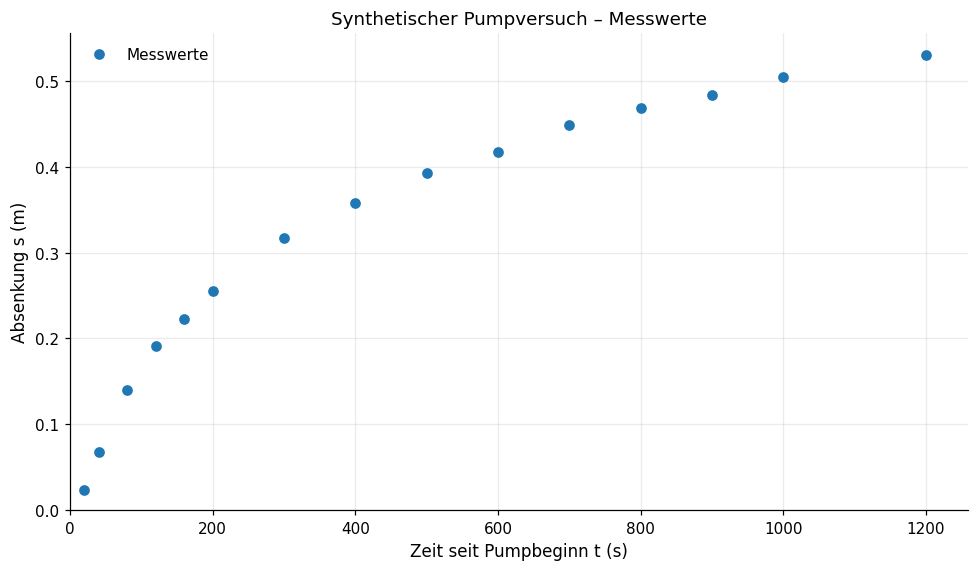

In [3]:
fig, ax = plt.subplots()
ax.plot(t_synth, s_synth, "o", ms=6, label="Messwerte")
ax.set(xlabel="Zeit seit Pumpbeginn t (s)", ylabel="Absenkung s (m)",
       title="Synthetischer Pumpversuch – Messwerte")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Theis-Anpassung – doppellogarithmische Darstellung

Die **vollständige Theis-Lösung** wird an **alle Messwerte** angepasst. Zur Beurteilung der Kurvenform stellen wir die Absenkung gegen die Zeit auf **beiden Achsen logarithmisch** dar.

Theis-Anpassung (synthetische Daten, alle Messpunkte)
T = 9.86962e-04 m²/s (Vorgabe: 1.00000e-03 m²/s)
S = 1.01590e-03 (Vorgabe: 1.00000e-03)
RMSE = 0.00242 m


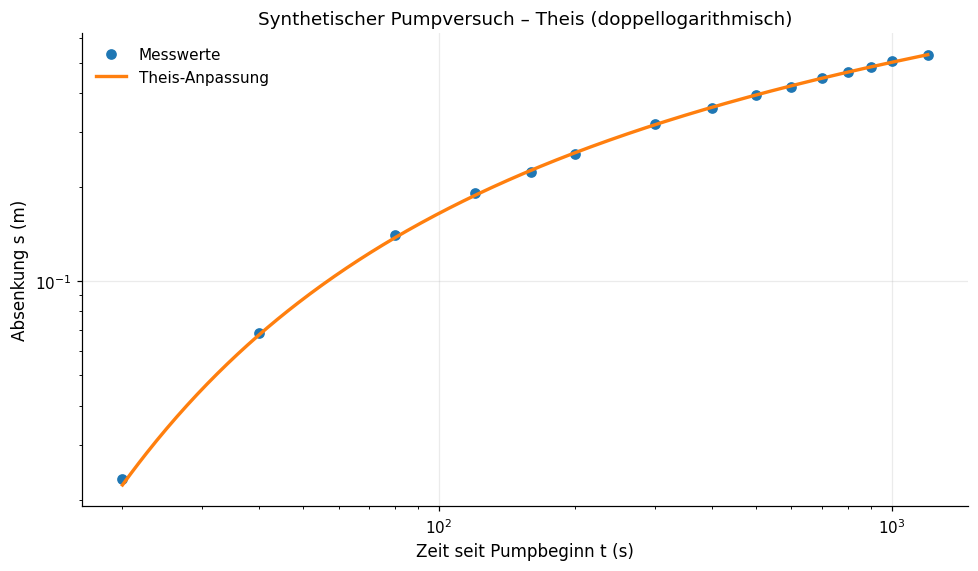

In [4]:
S_theis_synth, T_theis_synth = fit_theis(t_synth, s_synth, Q_synth, r_synth)
s_theis_synth = theis_drawdown(t_synth, Q_synth, r_synth, S_theis_synth, T_theis_synth)
t_plot_synth = np.geomspace(t_synth.min(), t_synth.max(), 400)

print("Theis-Anpassung (synthetische Daten, alle Messpunkte)")
print(f"T = {T_theis_synth:.5e} m²/s (Vorgabe: {T_true:.5e} m²/s)")
print(f"S = {S_theis_synth:.5e} (Vorgabe: {S_true:.5e})")
print(f"RMSE = {rmse(s_synth, s_theis_synth):.5f} m")

fig, ax = plt.subplots()
ax.loglog(t_synth, s_synth, "o", ms=6, label="Messwerte")
ax.loglog(t_plot_synth, theis_drawdown(t_plot_synth, Q_synth, r_synth,
                                      S_theis_synth, T_theis_synth),
          "-", lw=2.2, label="Theis-Anpassung")
ax.set(xlabel="Zeit seit Pumpbeginn t (s)", ylabel="Absenkung s (m)",
       title="Synthetischer Pumpversuch – Theis (doppellogarithmisch)")
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Cooper–Jacob-Auswertung – halblogarithmische Darstellung

Wir passen zwei Geraden an, um den Einfluss früher Messwerte zu zeigen:

- **Alle Messwerte:** als Vergleich, nicht automatisch als gültige Cooper–Jacob-Auswertung.
- **Ohne die ersten drei Messwerte:** die Zahl kann mit `n_exclude_synth = 3` verändert werden.

**Nur die Zeitachse ist logarithmisch**, die Absenkung bleibt linear. Die vollständige Theis-Kurve wird **nicht** in dieses Diagramm eingezeichnet.

**Wichtig zur Gültigkeit:** Ob die zur Regression verwendeten Messpunkte den Richtwert **u ≤ 0,02** erfüllen, wird anschließend anhand der **aus der Cooper–Jacob-Anpassung geschätzten Werte für T und S** geprüft. Die Geraden dienen hier vor allem dem **didaktischen Vergleich** der Messpunktauswahl. Eine gute Geradenanpassung allein bestätigt die Gültigkeit der Näherung nicht.

Cooper–Jacob-Auswertung (synthetische Daten)
Alle Messwerte            : T = 1.21790e-03 m²/s, S = 6.57127e-04
Ohne erste 3 Messpunkte   : T = 1.06132e-03 m²/s, S = 8.51357e-04
Ausgewählt: 12 von 15 Messpunkten
Gültigkeitsprüfung der Cooper–Jacob-Näherung (u ≤ 0.02)
  Verwendete Messpunkte: 12
  Davon erfüllen das Kriterium: 1
  Größter u-Wert: 0.1671
  ACHTUNG: Einige Punkte überschreiten den gewählten u-Richtwert.


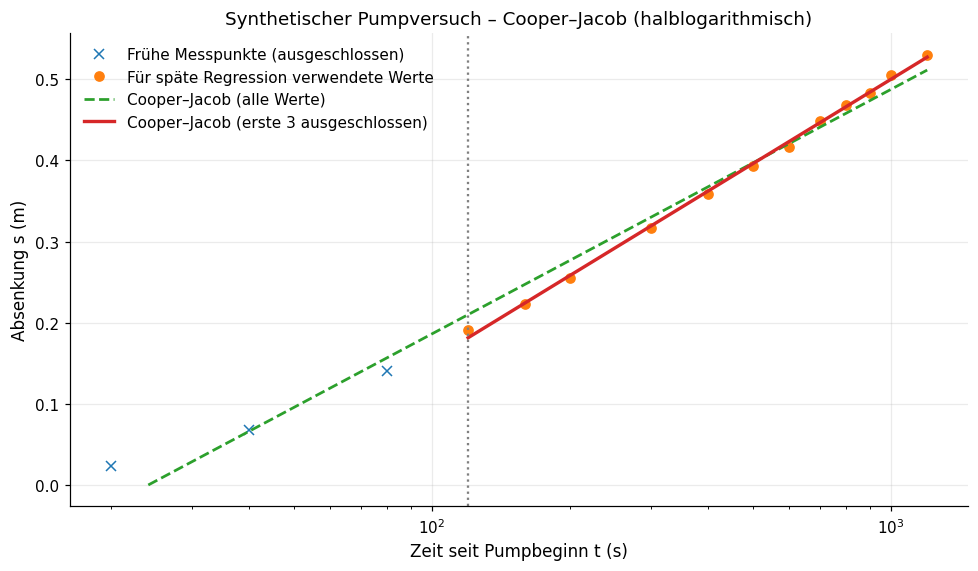

In [5]:
n_exclude_synth = 3  # Anzahl der nicht verwendeten frühen Messpunkte
cj_synth_all = fit_cooper_jacob(t_synth, s_synth, Q_synth, r_synth, n_exclude=0)
cj_synth_late = fit_cooper_jacob(t_synth, s_synth, Q_synth, r_synth,
                                  n_exclude=n_exclude_synth)
selected_synth = cj_synth_late["selected"]

print("Cooper–Jacob-Auswertung (synthetische Daten)")
for title, fit in [("Alle Messwerte", cj_synth_all),
                   ("Ohne erste 3 Messpunkte", cj_synth_late)]:
    print(f"{title:<26}: T = {fit['T']:.5e} m²/s, S = {fit['S']:.5e}")
print(f"Ausgewählt: {selected_synth.sum()} von {len(t_synth)} Messpunkten")
check_cj_validity(t_synth, Q_synth, r_synth, cj_synth_late)

fig, ax = plt.subplots()
ax.semilogx(t_synth[~selected_synth], s_synth[~selected_synth],
            "x", ms=7, label="Frühe Messpunkte (ausgeschlossen)")
ax.semilogx(t_synth[selected_synth], s_synth[selected_synth],
            "o", ms=6, label="Für späte Regression verwendete Werte")

# Beide Geraden nur im Bereich positiver angenäherter Absenkungen darstellen.
t_fit_all = np.geomspace(t_synth.min(), t_synth.max(), 350)
t_fit_late = np.geomspace(t_synth[n_exclude_synth], t_synth.max(), 300)
s_fit_all = cj_drawdown(t_fit_all, cj_synth_all)
ax.semilogx(t_fit_all, np.where(s_fit_all > 0, s_fit_all, np.nan),
            "--", lw=1.8, label="Cooper–Jacob (alle Werte)")
ax.semilogx(t_fit_late, cj_drawdown(t_fit_late, cj_synth_late),
            "-", lw=2.2, label=f"Cooper–Jacob (erste {n_exclude_synth} ausgeschlossen)")
ax.axvline(t_synth[n_exclude_synth], ls=":", color="0.5")
ax.set(xlabel="Zeit seit Pumpbeginn t (s)", ylabel="Absenkung s (m)",
       title="Synthetischer Pumpversuch – Cooper–Jacob (halblogarithmisch)")
ax.legend()
plt.tight_layout()
plt.show()

### 3.4 Interpretation

Die Theis-Anpassung verwendet die vollständige Brunnenfunktion und kann daher auch frühe Messzeiten berücksichtigen. Die Cooper–Jacob-Methode ersetzt die anfangs gekrümmte Theis-Kurve durch eine Gerade. Durch den Ausschluss früher Punkte verändert sich diese Gerade und damit auch die Parameterschätzung.

**Wichtig:** Bei der hier gewählten Messreihe lässt sich die Grenze **u ≤ 0,02** nicht allein durch den Ausschluss der ersten drei Punkte sicherstellen. Wer eine gültige Cooper–Jacob-Näherung nach diesem Kriterium demonstrieren möchte, benötigt genügend späte Messungen bzw. einen längeren Pumpversuch. Die vorliegenden Daten bleiben bewusst unverändert.

## 4. Beispiel 2 – Pumpversuchsmessdaten (Aufgabe a)

Die folgenden Messwerte und Pumpversuchsangaben stammen aus dem ursprünglichen Notebook und werden unverändert übernommen. Die Entnahmerate beträgt **Q = 0,006 m³/s**, die Entfernung der Messstelle **r = 40 m**. Gesucht sind **T** und **S**.

Wie im synthetischen Beispiel folgen drei Darstellungen: **linear für die Messwerte**, **doppellogarithmisch für Theis** und **halblogarithmisch für Cooper–Jacob**.

In [6]:
# Eingabedaten Aufgabe a (unverändert)
Q_real = 0.006   # m³/s
r_real = 40.0    # m
t_real = np.array([10, 18, 32, 57, 100, 178, 316,
                   562, 1000, 1780, 3160, 5620, 10000], dtype=float)  # s
s_real = np.array([0.005, 0.02, 0.05, 0.09, 0.16, 0.23, 0.31,
                   0.40, 0.49, 0.58, 0.67, 0.75, 0.82], dtype=float)  # m

assert np.all(np.diff(t_real) > 0) and len(t_real) == len(s_real)
assert np.all(s_real > 0)

### 4.1 Messwerte – lineare Darstellung

Zunächst werden nur die Messwerte dargestellt; Zeit und Absenkung sind **linear skaliert**.

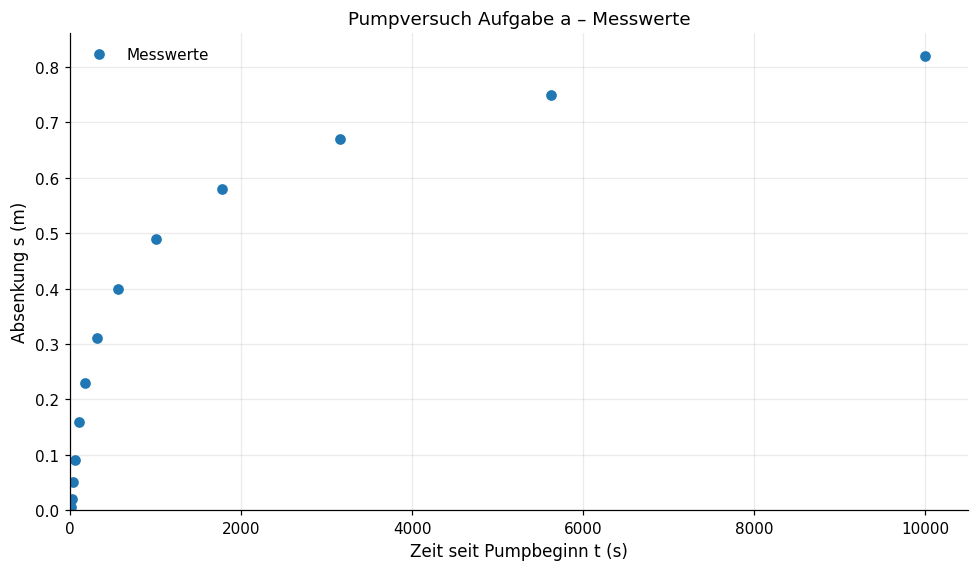

In [7]:
fig, ax = plt.subplots()
ax.plot(t_real, s_real, "o", ms=6, label="Messwerte")
ax.set(xlabel="Zeit seit Pumpbeginn t (s)", ylabel="Absenkung s (m)",
       title="Pumpversuch Aufgabe a – Messwerte")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 Theis-Anpassung – doppellogarithmische Darstellung

Die Theis-Kurve wird mittels nichtlinearer Regression an **alle 13 Messwerte** angepasst. Die Darstellung erfolgt **doppellogarithmisch**. Der **RMSE** wird in Metern angegeben.

Theis-Anpassung – Aufgabe a
T = 3.08536e-03 m²/s
S = 1.94614e-04
RMSE (alle Messpunkte) = 0.00692 m


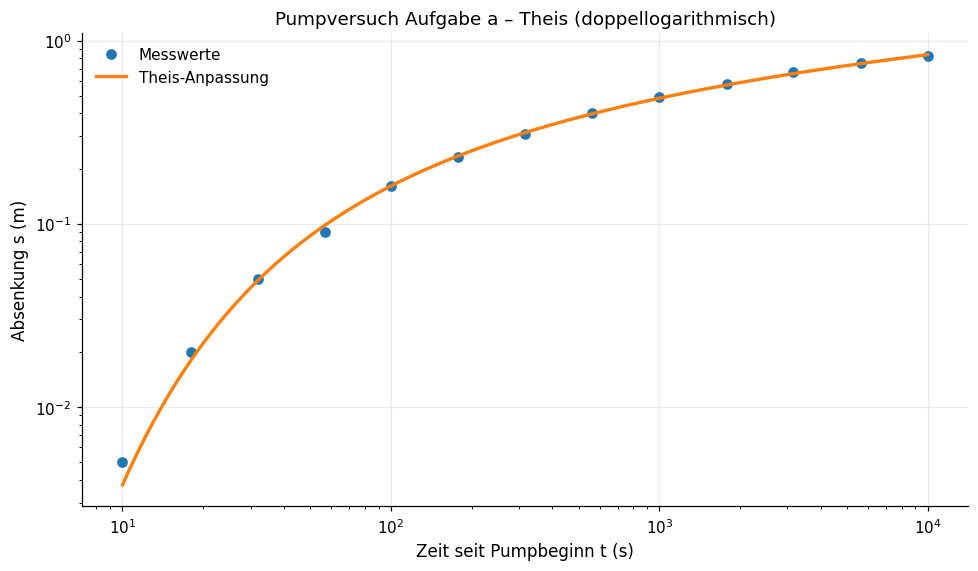

In [8]:
S_theis_real, T_theis_real = fit_theis(t_real, s_real, Q_real, r_real,
                                       S0=1e-4, T0=3e-3)
pred_theis_real = theis_drawdown(t_real, Q_real, r_real,
                                 S_theis_real, T_theis_real)
t_plot_real = np.geomspace(t_real.min(), t_real.max(), 400)

print("Theis-Anpassung – Aufgabe a")
print(f"T = {T_theis_real:.5e} m²/s")
print(f"S = {S_theis_real:.5e}")
print(f"RMSE (alle Messpunkte) = {rmse(s_real, pred_theis_real):.5f} m")

fig, ax = plt.subplots()
ax.loglog(t_real, s_real, "o", ms=6, label="Messwerte")
ax.loglog(t_plot_real, theis_drawdown(t_plot_real, Q_real, r_real,
                                     S_theis_real, T_theis_real),
          "-", lw=2.2, label="Theis-Anpassung")
ax.set(xlabel="Zeit seit Pumpbeginn t (s)", ylabel="Absenkung s (m)",
       title="Pumpversuch Aufgabe a – Theis (doppellogarithmisch)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.3 Cooper–Jacob-Auswertung – halblogarithmische Darstellung

Für die Gerade werden **nur die ersten drei Messpunkte ausgeschlossen**. Sie bleiben zur Orientierung im Diagramm sichtbar. Alle übrigen Punkte gehen in die Regression ein. Die x-Achse ist logarithmisch, die y-Achse linear. **Die Theis-Kurve erscheint hier nicht.**

Da nicht jeder ausgewählte Messpunkt zwangsläufig **u ≤ 0,02** erfüllt, berechnen wir anschließend die **u-Werte mit den geschätzten Cooper–Jacob-Parametern** und weisen mögliche Überschreitungen aus. Zum Vergleich werden die Anpassungsfehler beider Verfahren **für dieselben ausgewählten Messpunkte** angegeben.

Cooper–Jacob-Auswertung – Aufgabe a
Ausgewählt: 10 von 13 Messpunkten
T = 3.28164e-03 m²/s
S = 1.56924e-04
Steigung m = 0.33502 m pro Dekade
Zeitachsenabschnitt t₀ = 34.07 s
RMSE (CJ, ausgewählter Bereich) = 0.00921 m
RMSE (Theis, gleicher Bereich) = 0.00785 m
Gültigkeitsprüfung der Cooper–Jacob-Näherung (u ≤ 0.02)
  Verwendete Messpunkte: 10
  Davon erfüllen das Kriterium: 5
  Größter u-Wert: 0.3356
  ACHTUNG: Einige Punkte überschreiten den gewählten u-Richtwert.


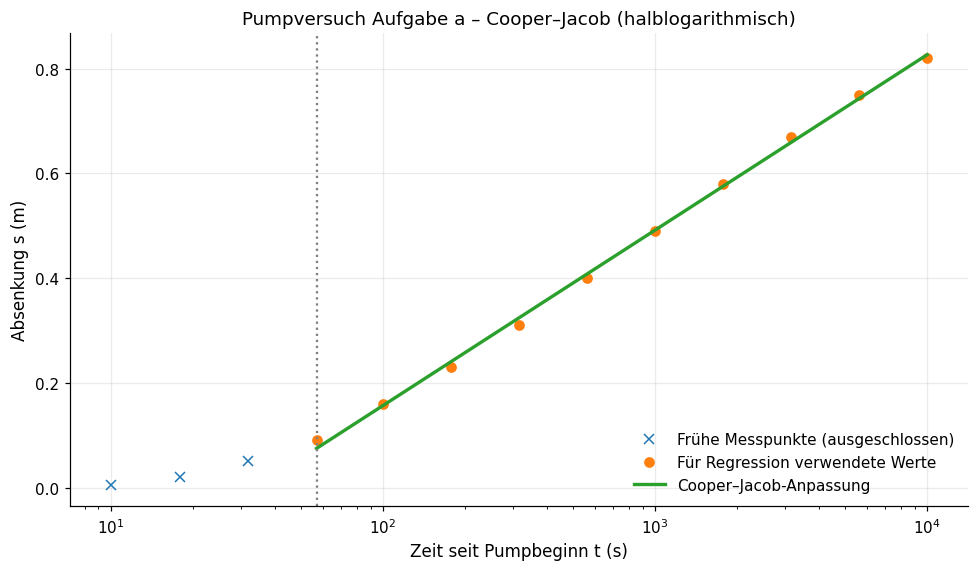

In [9]:
n_exclude_real = 3  # Anzahl der nicht verwendeten frühen Messpunkte
cj_real = fit_cooper_jacob(t_real, s_real, Q_real, r_real,
                            n_exclude=n_exclude_real)
selected_real = cj_real["selected"]
pred_cj_real = cj_drawdown(t_real[selected_real], cj_real)

print("Cooper–Jacob-Auswertung – Aufgabe a")
print(f"Ausgewählt: {selected_real.sum()} von {len(t_real)} Messpunkten")
print(f"T = {cj_real['T']:.5e} m²/s")
print(f"S = {cj_real['S']:.5e}")
print(f"Steigung m = {cj_real['m']:.5f} m pro Dekade")
print(f"Zeitachsenabschnitt t₀ = {cj_real['t0']:.2f} s")
print(f"RMSE (CJ, ausgewählter Bereich) = {rmse(s_real[selected_real], pred_cj_real):.5f} m")
print(f"RMSE (Theis, gleicher Bereich) = {rmse(s_real[selected_real], pred_theis_real[selected_real]):.5f} m")
check_cj_validity(t_real, Q_real, r_real, cj_real)

fig, ax = plt.subplots()
ax.semilogx(t_real[~selected_real], s_real[~selected_real],
            "x", ms=7, label="Frühe Messpunkte (ausgeschlossen)")
ax.semilogx(t_real[selected_real], s_real[selected_real],
            "o", ms=6, label="Für Regression verwendete Werte")
t_fit_cj_real = np.geomspace(t_real[n_exclude_real], t_real.max(), 350)
ax.semilogx(t_fit_cj_real, cj_drawdown(t_fit_cj_real, cj_real),
            "-", lw=2.2, label="Cooper–Jacob-Anpassung")
ax.axvline(t_real[n_exclude_real], ls=":", color="0.5")
ax.set(xlabel="Zeit seit Pumpbeginn t (s)", ylabel="Absenkung s (m)",
       title="Pumpversuch Aufgabe a – Cooper–Jacob (halblogarithmisch)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.4 Residuen – ergänzende Qualitätskontrolle

Als Residuum wird die Differenz **gemessene Absenkung minus modellierte Absenkung** bezeichnet. Beide Verfahren werden in einem eigenen Diagnosebild verglichen. **Hier wird keine Theis-Kurve dargestellt**, sondern nur die Residuen an den Messzeitpunkten; beide Achsen sind linear skaliert.

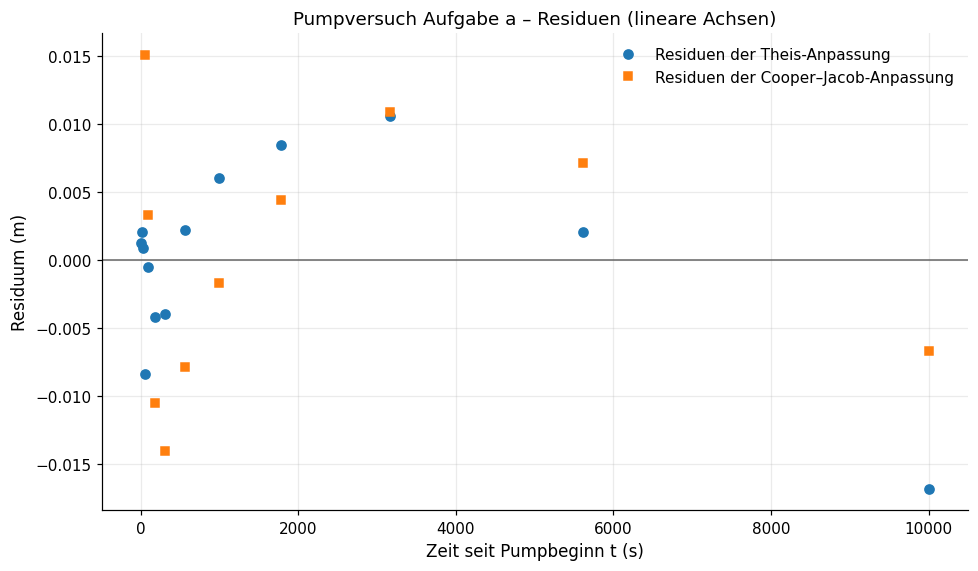

In [10]:
fig, ax = plt.subplots()
ax.plot(t_real, s_real - pred_theis_real, "o", ms=6,
        label="Residuen der Theis-Anpassung")
ax.plot(t_real[selected_real], s_real[selected_real] - pred_cj_real,
        "s", ms=5.5, label="Residuen der Cooper–Jacob-Anpassung")
ax.axhline(0, color="0.4", lw=1)
ax.set(xlabel="Zeit seit Pumpbeginn t (s)", ylabel="Residuum (m)",
       title="Pumpversuch Aufgabe a – Residuen (lineare Achsen)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Beispiel 3 – Absenkung berechnen (Aufgabe b)

Bei einer **Vorwärtsrechnung** sind **Q**, **r**, **S**, **T** und die Zeit **t** vorgegeben. Aus der Theis-Gleichung wird die Absenkung **s** berechnet. Gesucht ist hier die Absenkung **nach einem Tag** (86.400 s). Dieses Beispiel ist unabhängig von den zuvor geschätzten Parametern.

In [11]:
# Eingabedaten Aufgabe b (unverändert)
Q_predict = 0.0053  # m³/s
r_predict = 100.0  # m
S_predict = 0.0001  # –
T_predict = 0.001   # m²/s
t_predict = 24 * 60 * 60  # s (1 Tag)

s_predict = float(theis_drawdown(t_predict, Q_predict, r_predict,
                                 S_predict, T_predict))
print("Aufgabe b – Berechnung der Absenkung")
print(f"Q = {Q_predict:.4f} m³/s, r = {r_predict:.1f} m")
print(f"T = {T_predict:.3e} m²/s, S = {S_predict:.3e}")
print(f"t = {t_predict:,.0f} s")
print(f"Absenkung nach einem Tag: s = {s_predict:.3f} m")

Aufgabe b – Berechnung der Absenkung
Q = 0.0053 m³/s, r = 100.0 m
T = 1.000e-03 m²/s, S = 1.000e-04
t = 86,400 s
Absenkung nach einem Tag: s = 2.223 m


## 6. Zusammenfassung und Hinweise

| Auswertung | Darstellung | Verwendete Messwerte |
|:---|:---|:---|
| Beobachtete Absenkung | **linear / linear** | alle |
| Vollständige Theis-Lösung | **doppellogarithmisch** | alle |
| Cooper–Jacob-Gerade | **halblogarithmisch** (Zeit logarithmisch) | konfigurierbar, standardmäßig ab dem 4. Messwert |

- **Theis** kann den gesamten idealisierten Verlauf abbilden, sofern die Modellannahmen erfüllt sind.
- **Cooper–Jacob** ist eine Näherung für kleine **u**. Hier wird der in der Literatur angegebene Richtwert **u ≤ 0,02** (Freeze & Cherry, 1979) verwendet. Ein bloßer Ausschluss der ersten drei Messpunkte garantiert **nicht**, dass die Näherung gültig ist.
- **T** ist im vorliegenden Beispiel vergleichsweise stabil; **S** ist stärker von der Wahl des Auswertebereichs und von der Extrapolation zum Zeitachsenabschnitt abhängig.
- Die **RMSE-Werte** beschreiben die Anpassung an die Daten; sie ersetzen nicht die hydrogeologische Prüfung der Modellannahmen.

**Zum Ausprobieren:** Ändern Sie `n_exclude_synth` bzw. `n_exclude_real` auf 2, 4 oder 5 und vergleichen Sie die Ergebnisse und die Gültigkeitskontrolle. Variieren Sie beim synthetischen Beispiel außerdem `random_seed` oder `relative_noise`.

### Literatur

**Grundlagen der Verfahren**

- Theis, C. V. (1935): *The relation between the lowering of the piezometric surface and the rate and duration of discharge of a well using ground-water storage.* Transactions, American Geophysical Union, 16(2), 519–524. [DOI](https://doi.org/10.1029/TR016i002p00519).
- Cooper, H. H., Jr. & Jacob, C. E. (1946): *A generalized graphical method for evaluating formation constants and summarizing well-field history.* Transactions, American Geophysical Union, 27(4), 526–534. [DOI](https://doi.org/10.1029/TR027i004p00526).

**Gültigkeitsbereich der Cooper–Jacob-Näherung**

- Kruseman, G. P. & de Ridder, N. A. (1990; Nachdruck 1991): *Analysis and Evaluation of Pumping Test Data.* 2., vollständig überarbeitete Auflage, ILRI Publication 47, Wageningen (unter Mitarbeit von J. M. Verweij). [Online-Ausgabe](https://gw-project.org/books/analysis-and-evaluation-of-pumping-test-data/). Richtwert: **u ≤ 0,01**.
- Freeze, R. A. & Cherry, J. A. (1979): *Groundwater.* Prentice-Hall, Englewood Cliffs, New Jersey. [Online-Ausgabe](https://fc79.gw-project.org/). Richtwert: **u ≤ 0,02**.
- Fetter, C. W. (2001): *Applied Hydrogeology.* 4. Auflage, Prentice Hall, Upper Saddle River, New Jersey. Richtwert: **u ≤ 0,05**.
- Gomo, M. (2020): *On the practical application of the Cooper and Jacob distance-drawdown method to analyse aquifer-pumping test data.* Groundwater for Sustainable Development, 11, 100478. [DOI](https://doi.org/10.1016/j.gsd.2020.100478). Diskutiert unterschiedliche u-Grenzwerte und die Bedeutung der Ausbildung radialer Strömungsverhältnisse für die Anwendbarkeit der Methode.

Die genannten Grenzwerte sind **Richtwerte aus der Literatur**, keine scharfen physikalischen Grenzen. Weitere Modellannahmen müssen unabhängig davon geprüft werden.